# Mouse immune: cell-type annotation (stage 04c)

Every cluster of the re-integrated immune lineage is assigned one cell type (or EXCLUDE). Labels are the vocabulary in resources/annotation_vocabulary.yaml.

Clustering: `data/interim/latent_mouse_immune.h5ad`, column `leiden_scVI_3.0`. Decisions: `resources/annotations/mouse_immune.csv`, one
row per cluster with the markers that justify the label in `note`. Nothing in this
notebook assigns a label; it shows the evidence the table was decided from.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook kernels start in notebooks/annotation/, so the repo root is two levels up.
REPO = Path("../..").resolve()
if not (REPO / "resources/annotations").is_dir():
    raise FileNotFoundError(f"{REPO} is not the repository root")
SPECIES, LEVEL, RESOLUTION = "mouse", "immune", "leiden_scVI_3.0"
OBJECT = REPO / "data/interim/latent_mouse_immune.h5ad"
TABLE = REPO / "resources/annotations/mouse_immune.csv"
PANEL = ['Ptprc', 'Adgre1', 'Csf1r', 'C1qa', 'C1qb', 'Mrc1', 'Itgax', 'Cd3e', 'Cd3d', 'Cd79a', 'Ms4a1', 'Ncr1', 'Gzmb', 'Prf1', 'Eomes', 'Mki67', 'Top2a', 'Cdh1', 'Pdgfra', 'Pecam1', 'Myh11', 'Sox6', 'Ly6c2', 'Ccr2', 'Plac8', 'Flt3', 'Xcr1', 'H2-Ab1', 'Cd4', 'Cd8a', 'Trdc', 'Itga1', 'Gzmc']
sc.settings.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_colwidth", 200)

## 1. The committed table

In [2]:
table = pd.read_csv(TABLE, dtype={"cluster": str})
table.set_index("cluster")

,label,n_cells,res,note
cluster,,,,
0,macrophage,84,leiden_scVI_3.0,"Adgre1 0.51; C1qa 0.17; Mrc1 0.65; Csf1r 0.45 | top vs lineage: Pbx1 0.57, Zeb2 0.93, Tshz2 0.51"
1,macrophage,83,leiden_scVI_3.0,"Adgre1 0.70; C1qa 0.23; Mrc1 0.75; Csf1r 0.66 | top vs lineage: Tmcc3 0.92, Plxdc2 0.70, Gab2 0.92"
2,macrophage,26,leiden_scVI_3.0,"Adgre1 0.50; C1qa 0.19; Mrc1 0.62; Csf1r 0.42 | top vs lineage: Magi1 0.73, Tcf4 0.96, Ptprm 0.77"
3,macrophage,93,leiden_scVI_3.0,"Adgre1 0.55; C1qa 0.23; Mrc1 0.96; Csf1r 0.52 | top vs lineage: F13a1 0.84, Frmd4b 0.95, Wwp1 0.89"
4,unk_cell_proliferative,154,leiden_scVI_3.0,"Ncr1 0.47; Eomes 0.23; Mki67 0.57; Top2a 0.58 | top vs lineage: Arsb 0.85, Skap1 0.90, Atp8b4 0.84"
5,dendritic_cell,90,leiden_scVI_3.0,"Flt3 0.72; Xcr1 0.26; H2-Ab1 0.44; Itgax 0.10 | top vs lineage: Wdfy4 0.99, Fnbp1 0.97, Camk1d 0.97"
6,t_cell_gamma_delta,55,leiden_scVI_3.0,"Trdc 0.11; Cd3e 0.11; Cd3d 0.00 | top vs lineage: St6galnac3 0.93, Camk4 0.73, Bcl11b 0.69"
7,monocyte,96,leiden_scVI_3.0,"Ly6c2 0.00; Ccr2 0.45; Plac8 0.01; Csf1r 0.12 | top vs lineage: Alcam 0.91, Trerf1 0.85, Ext1 0.93"
8,macrophage,82,leiden_scVI_3.0,"Adgre1 0.60; C1qa 0.26; Mrc1 0.76; Csf1r 0.39 | top vs lineage: Sash1 0.82, Fnip2 0.73, Psap 0.73"


## 2. The clustered object (must carry exactly the clusters in the table)

In [3]:
adata = ad.read_h5ad(OBJECT)
adata.obs["cluster"] = adata.obs[RESOLUTION].astype(str)
in_object, in_table = set(adata.obs["cluster"]), set(table["cluster"])
if in_object != in_table:
    raise ValueError(f"cluster sets differ: object-only {sorted(in_object - in_table)}, "
                     f"table-only {sorted(in_table - in_object)}")
labels = table.set_index("cluster")["label"]
adata.obs["label"] = adata.obs["cluster"].map(labels).astype("category")
print(adata.n_obs, "nuclei;", len(in_object), "clusters")
print(adata.obs["label"].value_counts().to_dict())

2091 nuclei; 29 clusters
{'macrophage': 797, 'unk_cell': 436, 'monocyte': 204, 'unk_cell_proliferative': 154, 'macrophage_proliferative': 150, 't_cell': 97, 'dendritic_cell': 90, 'unk_cell_cytotoxic': 73, 't_cell_gamma_delta': 55, 'b_cell': 35}


In [4]:
# Expression for the dot plot: CP10K log1p from raw counts.
counts = adata.layers["counts"] if "counts" in adata.layers else adata.X
expr = ad.AnnData(X=counts.copy(), obs=adata.obs[["cluster", "label"]].copy(),
                  var=adata.var[[]].copy())
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
genes = [g for g in PANEL if g in expr.var_names]
missing = sorted(set(PANEL) - set(genes))
if missing:
    print("not in this object:", missing)

## 3. Marker dot plot by cluster

Dot size is the fraction of nuclei in which the gene is detected, colour the mean
log1p CP10K. Clusters are grouped by their label; EXCLUDE clusters are last.

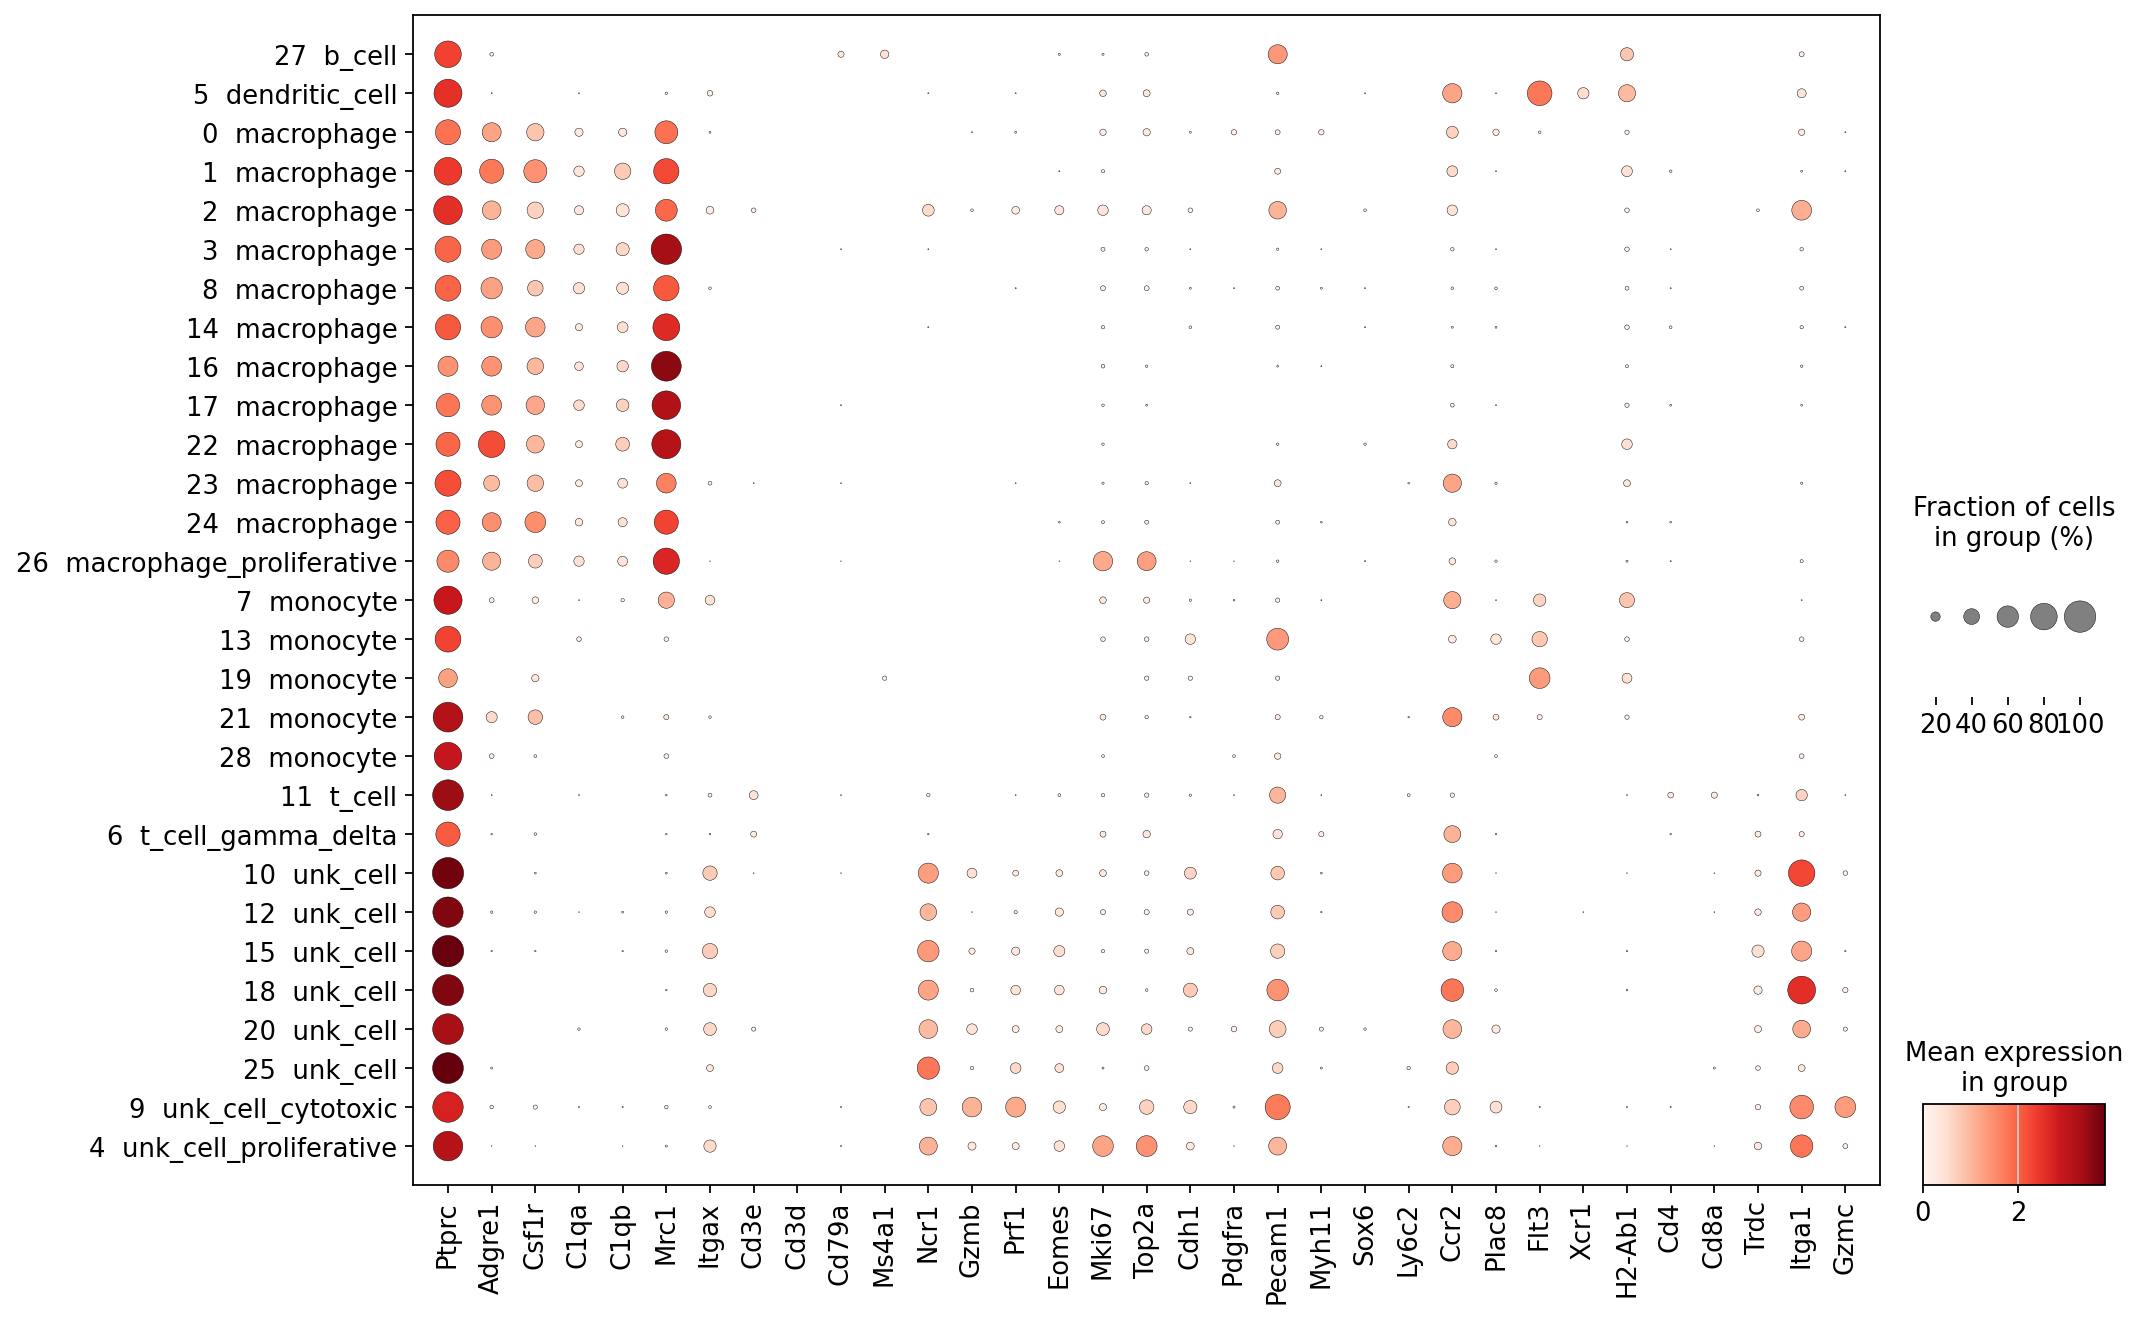

In [5]:
def sort_key(c):
    return (labels[c] == "EXCLUDE", labels[c], int(c) if c.isdigit() else c)

order = sorted(in_object, key=sort_key)
expr.obs["cluster_labelled"] = pd.Categorical(
    [f"{c}  {labels[c]}" for c in expr.obs["cluster"]],
    categories=[f"{c}  {labels[c]}" for c in order])
sc.pl.dotplot(expr, genes, groupby="cluster_labelled", standard_scale=None,
              figsize=(0.32 * len(genes) + 3, 0.28 * len(order) + 1.5))

## 4. QC per cluster

Median DoubletDetection score and genes per nucleus per cluster, with the lineage
median for reference. A high doublet score together with markers of another lineage
(section 6) is what an EXCLUDE call rests on; a moderate score alone is not
(cycling clusters score around 1 throughout this dataset).

In [6]:
qc_cols = [c for c in ("doubletdetection_doublet_score", "n_genes_by_counts",
                       "total_counts") if c in adata.obs]
qc = adata.obs.groupby("cluster", observed=True)[qc_cols].median().loc[order]
qc.insert(0, "n", adata.obs["cluster"].value_counts().loc[order])
qc.insert(1, "label", labels.loc[order])
qc.loc["lineage median"] = [adata.n_obs, ""] + list(adata.obs[qc_cols].median())
qc.round(2)

,n,label,doubletdetection_doublet_score,n_genes_by_counts,total_counts
cluster,,,,,
27,35,b_cell,0.00,710.0,987.0
5,90,dendritic_cell,0.00,971.0,1431.0
0,84,macrophage,0.05,1201.0,1707.0
1,83,macrophage,0.00,1184.0,1745.0
2,26,macrophage,0.10,1784.0,2998.0
3,93,macrophage,0.00,1154.0,1654.0
8,82,macrophage,0.00,1338.5,2013.0
14,79,macrophage,0.00,986.0,1399.0
16,89,macrophage,0.00,824.0,1098.0


## 5. UMAP by cluster and by label

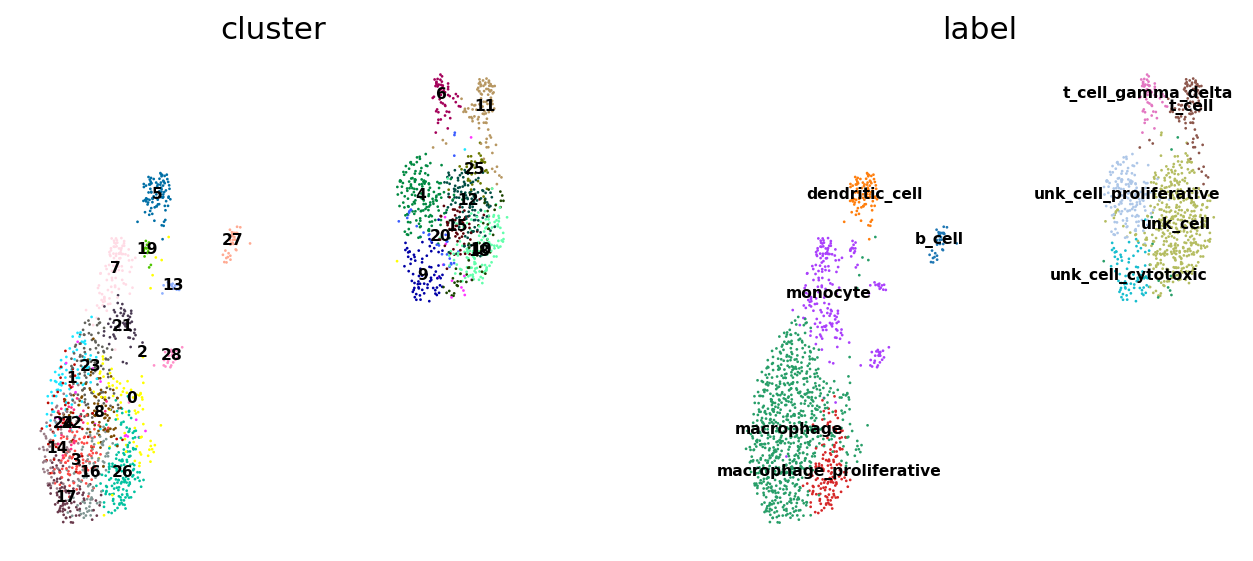

In [7]:
umap_key = next((k for k in ("X_umap_scVI", "X_umap") if k in adata.obsm), None)
if umap_key is None:
    latent_key = next(k for k in adata.obsm if "scVI" in k or "scvi" in k)
    sc.pp.neighbors(adata, use_rep=latent_key, n_neighbors=15, random_state=0)
    sc.tl.umap(adata, random_state=0)
    umap_key = "X_umap"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=["cluster", "label"], legend_loc="on data",
                    legend_fontsize=7, size=6, ncols=2, wspace=0.25)

## 6. EXCLUDE clusters

Detection of each lineage's markers inside the excluded clusters, next to the
lineage-wide detection; a cluster is excluded when it carries another lineage's
programme (doublets) or too little RNA to call.

In [8]:
excluded = [c for c in order if labels[c] == "EXCLUDE"]
if excluded:
    detected = pd.DataFrame(
        {c: np.asarray((expr[expr.obs["cluster"] == c, genes].X > 0).mean(0)).ravel()
         for c in excluded},
        index=genes)
    detected["lineage"] = np.asarray((expr[:, genes].X > 0).mean(0)).ravel()
    display(detected.round(2).T)
else:
    print("no EXCLUDE clusters in this table")

no EXCLUDE clusters in this table
